In [1]:
#!/usr/bin/env python3

import os, sys,glob
sys.path.append('../')
import numpy as np
from matplotlib import pyplot as plt
import matplotlib as mpl
from collections import namedtuple
import pandas as pd
from helper import getModelDict
from triggers_helper import in_N,in_Np1,in_ms,in_hcal
try:
    import mplhep as hep
    hep.style.use("ATLAS")
except:
    pass
delphesDir = os.path.abspath("../../DelphesLLP")
os.environ['ROOT_INCLUDE_PATH'] = os.path.join(delphesDir,"external")

import ROOT


ROOT.gSystem.Load(os.path.join(delphesDir,"libDelphes.so"))

ROOT.gInterpreter.Declare('#include "classes/SortableObject.h"')
ROOT.gInterpreter.Declare('#include "classes/DelphesClasses.h"')
ROOT.gInterpreter.Declare('#include "external/ExRootAnalysis/ExRootTreeReader.h"')



Welcome to JupyROOT 6.30/06


True

In [2]:
def get_labels(df_selected,all_df=[],full_label=False):

    labels = {'mS' : lambda x: r'$m_S$ =' + f' {x:1.2f} [GeV]',
          'm1' : lambda x: r'$m_{\chi_1}$ =' + f' {x:1.2f} [GeV]',
          'dm' : lambda x: r'$\Delta m$ =' + f' {x:1.2f} [GeV]',
          'tau' : lambda x: r'$c \tau$ =' + f' {x*3e8:1.0f} [m]',
        #   'm0' : lambda x: r'$m_{\chi_0}$ =' + f' {x:1.2f} [GeV]',
        #   'm2' : lambda x: r'$m_{\chi_2}$ =' + f' {x:1.2f} [GeV]'          
         }

    model_label = [labels[k](float(df_selected[k].values[0])) for k in labels if k in df_selected.columns]
    if full_label:
        return ', '.join(model_label)
    all_labels = []
    for df in all_df:
        all_labels.append([labels[k](float(df[k].values[0])) for k in labels if k in df.columns])
    labelsDict = {}
    for labelList in all_labels:
        for label in labelList:
            labelsDict.setdefault(label,0)
            labelsDict[label] += 1
    common_labels = [l for l,c in labelsDict.items() if c == len(all_labels)]
    short_label = [l for l in model_label if l not in common_labels]
    short_label = ', '.join(short_label)
    common_label = ', '.join(common_labels)
    return short_label,common_label


def closestDF(dfList, point, relative=True):
    """Return the DataFrame with the parameters closest to point 
    (dict column -> value)."""
    min_dist = float('inf')
    closest_df = None
    for df in dfList:
        row = df.iloc[0]
        cols = list(point.keys())
        target = pd.Series(point)
        diff = row[cols] - target
        if relative:
            diff = diff / target.abs().where(target != 0, 1.0)   # relative difference (absolute if target is 0)
        dist = sum(diff**2)
        if dist < min_dist:
            min_dist = dist
            closest_df = df
    return closest_df   # double brackets keep it a DataFrame


## Read events

In [3]:
processFolders = '../../processFolders/pp2chi1chi2_01j_nosmear_13TeV_new'


runs = ['run_117','run_61', 'run_120']

files = []
for f in runs:
    runFolder = os.path.join(processFolders, 'Events', f)
    rootFile = list(glob.glob(os.path.join(runFolder, '*.root')))[0]
    files.append(rootFile)

c_light = 2.99792458e8

### Get Event information

In [ ]:
dfList = []
decayVertex = namedtuple('decayVertex',['x','y','z','t','beta','l','rho'])
for file in files:
    if not os.path.isfile(file):
        print(f"File {file} not found, skipping")
        continue
    f = ROOT.TFile(file,'read')
    tree = f.Get("Delphes")
    nevts = tree.GetEntries()
    rDecays = []
    metList = []
    modelData = getModelDict(file,verbose=False)
    modelData['dm'] = modelData['m1'] - modelData['m0']
    modelData['ctau'] = modelData['tau']*c_light
    for ievt in range(nevts):
        tree.GetEntry(ievt)

        llpDec = {}
        llpBoost = {}
        llps = list(tree.llpParticles)
        for illp,llp in enumerate(llps):
            p = np.array([llp.Px,llp.Py,llp.Pz,llp.E])
            beta = np.linalg.norm(p[:3])/p[3]
            llpBoost[illp] = beta
        
        for d in tree.llpDirectDaughters:
            illp = d.M1
            if illp in llpDec:
                continue
            beta = llpBoost[illp]
            decayVtx = decayVertex(d.X*1e-3,d.Y*1e-3,d.Z*1e-3,d.T,beta,
                                   float(np.linalg.norm([d.X,d.Y,d.Z])*1e-3),
                                   float(np.linalg.norm([d.X,d.Y])*1e-3))
            t_readout = decayVtx.t-decayVtx.l/c_light
            t_readout = t_readout*1e9
            llpDec[illp] = decayVtx._replace(t=t_readout)
        decs = sorted(llpDec.values(), key = lambda d : d[3])
        if len(decs) != 1:
            raise ValueError(f"Event {ievt} has {len(decs)} decays, expected 1")
        rDecays.append(decs[0])
        metList.append(tree.L1METOnTime.At(0).MET)
    f.Close()
    df = pd.DataFrame(rDecays, columns=decayVertex._fields)
    df['met'] = metList
    for k,v in modelData.items():
        df[k] = v
    dfList.append(df)


/home/lessa/back2futureTrigger/B2TF-Trigger/plots/../helper.py:106: UserWarning: genfromtxt: Empty input file: "../../processFolders/pp2chi1chi2_01j_nosmear_13TeV_new/Events/run_117/chi1chi2_01j_mS_500_m2_232_m1_227_dm_15_ctau_20.0_merged_xsecs.txt"
  xsecData = np.genfromtxt(xsecFile,skip_header=1)
/home/lessa/back2futureTrigger/B2TF-Trigger/plots/../helper.py:106: UserWarning: genfromtxt: Empty input file: "../../processFolders/pp2chi1chi2_01j_nosmear_13TeV_new/Events/run_61/chi1chi2_01j_mS_800_m2_400_m1_396_dm_15_ctau_20.0_merged_xsecs.txt"
  xsecData = np.genfromtxt(xsecFile,skip_header=1)
/home/lessa/back2futureTrigger/B2TF-Trigger/plots/../helper.py:106: UserWarning: genfromtxt: Empty input file: "../../processFolders/pp2chi1chi2_01j_nosmear_13TeV_new/Events/run_120/chi1chi2_01j_mS_500_m2_232_m1_227_dm_100_ctau_20.0_merged_xsecs.txt"
  xsecData = np.genfromtxt(xsecFile,skip_header=1)


In [5]:
for df in dfList:
    print(f"{get_labels(df, full_label=True)}: {len(df)} events")

$m_S$ = 500.00 [GeV], $m_{\chi_1}$ = 227.00 [GeV], $\Delta m$ = 15.00 [GeV], $c \tau$ = 20 [m]: 77960 events
$m_S$ = 800.00 [GeV], $m_{\chi_1}$ = 395.50 [GeV], $\Delta m$ = 15.00 [GeV], $c \tau$ = 20 [m]: 85551 events
$m_S$ = 500.00 [GeV], $m_{\chi_1}$ = 227.00 [GeV], $\Delta m$ = 100.00 [GeV], $c \tau$ = 20 [m]: 78536 events


### Split LLPs decaying in N-1 and N and in MS and HCAL

In [6]:
for df in dfList:
    df['ontime'] = in_N(df['t'])
    df['delayed'] = in_Np1(df['t'])
    df['in MS'] = in_ms(df['z'],df['rho'])
    df['in HCAL'] = in_hcal(df['z'],df['rho'])
    label = get_labels(df, full_label=True)
    print(f'\n{label} :\n decays in N = {sum(df["ontime"])/len(df):1.4f}, decays in N+1 = {sum(df["delayed"])/len(df):1.4f}')


$m_S$ = 500.00 [GeV], $m_{\chi_1}$ = 227.00 [GeV], $\Delta m$ = 15.00 [GeV], $c \tau$ = 20 [m] :
 decays in N = 0.3562, decays in N+1 = 0.2058

$m_S$ = 800.00 [GeV], $m_{\chi_1}$ = 395.50 [GeV], $\Delta m$ = 15.00 [GeV], $c \tau$ = 20 [m] :
 decays in N = 0.3225, decays in N+1 = 0.2161

$m_S$ = 500.00 [GeV], $m_{\chi_1}$ = 227.00 [GeV], $\Delta m$ = 100.00 [GeV], $c \tau$ = 20 [m] :
 decays in N = 0.3588, decays in N+1 = 0.2050


### Count decays in N+1 and MS

In [7]:
for df in dfList:
    label = get_labels(df, full_label=True)
    nMS_delayed = len(df[df['in MS'] & df['delayed']])/sum(df["delayed"])
    print(f'{label} :\n decays in MS = {nMS_delayed:1.4f}\n')

print("\nImposing MET > 200")
for df in dfList:
    label = get_labels(df, full_label=True)
    nMS_delayed = len(df[df['in MS'] & df['delayed'] & (df['met'] > 200)])/sum(df["delayed"])
    print(f'{label} :\n decays in MS = {nMS_delayed:1.4f}\n')
    


$m_S$ = 500.00 [GeV], $m_{\chi_1}$ = 227.00 [GeV], $\Delta m$ = 15.00 [GeV], $c \tau$ = 20 [m] :
 decays in MS = 0.2050

$m_S$ = 800.00 [GeV], $m_{\chi_1}$ = 395.50 [GeV], $\Delta m$ = 15.00 [GeV], $c \tau$ = 20 [m] :
 decays in MS = 0.1875

$m_S$ = 500.00 [GeV], $m_{\chi_1}$ = 227.00 [GeV], $\Delta m$ = 100.00 [GeV], $c \tau$ = 20 [m] :
 decays in MS = 0.2007


Imposing MET > 200
$m_S$ = 500.00 [GeV], $m_{\chi_1}$ = 227.00 [GeV], $\Delta m$ = 15.00 [GeV], $c \tau$ = 20 [m] :
 decays in MS = 0.0088

$m_S$ = 800.00 [GeV], $m_{\chi_1}$ = 395.50 [GeV], $\Delta m$ = 15.00 [GeV], $c \tau$ = 20 [m] :
 decays in MS = 0.0270

$m_S$ = 500.00 [GeV], $m_{\chi_1}$ = 227.00 [GeV], $\Delta m$ = 100.00 [GeV], $c \tau$ = 20 [m] :
 decays in MS = 0.0035



# Plots vs mS

In [48]:
selectPoints = [{'mS' : 500.0, 'dm' : 15.0, 'm1' : 227.0, 'ctau' : 20.0},  
                {'mS' : 800.0, 'dm' : 15.0, 'm1' : 395.0, 'ctau' : 20.0}]
df_filtered = [closestDF(dfList, point) for point in selectPoints]
common_label = get_labels(df_filtered[0], all_df=df_filtered, full_label=False)[1]

### MET Distribution

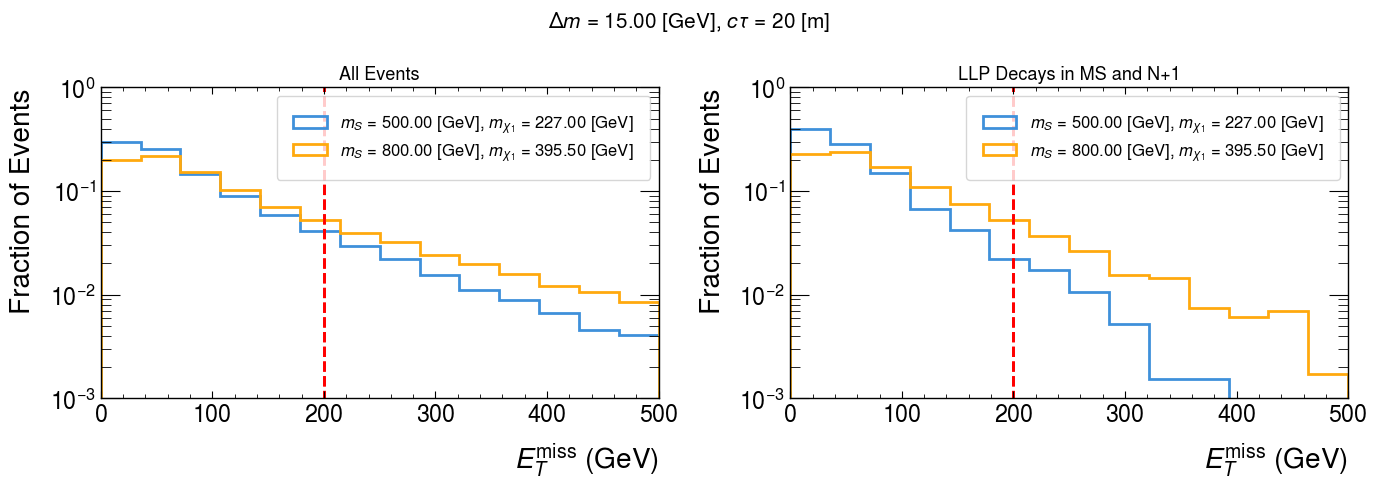

In [50]:

nrows, ncols = 1,2
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(7*ncols, 5*nrows))
axes = axes.flatten() if nrows*ncols > 1 else [axes]
plt.suptitle(common_label,fontsize=15)
for ax,inMS in zip(axes,[False,True]):
    if inMS:
        ax.set_title(fr'LLP Decays in MS and N+1',fontsize=13)
    else:
        ax.set_title(fr'All Events',fontsize=13)
    for df0 in df_filtered:
        if inMS:
            df = df0[df0['in MS'] & df0['delayed']]
        else:
            df = df0
        short_label = get_labels(df, all_df=df_filtered, full_label=False)[0]
        ax.hist(df['met'],bins=np.linspace(0.,500.0,15),
             histtype='step',
             weights=[1.0/len(df)]*len(df),
             label=f'{short_label}',linewidth=2)
        ax.set_yscale('log')
        ax.set_xlabel(r'$E_T^{\rm miss}$ (GeV)')
        ax.set_ylabel('Fraction of Events')
        ax.legend(loc='upper right',framealpha=0.8,frameon=True,fontsize=12)
        ax.set_ylim(1e-3,1.0)
        ax.grid()
        ax.vlines(x=200.,ymin=0.,ymax=1.0,color='red',linestyles='dashed')
plt.tight_layout()
plt.show()

### Boost Distribution

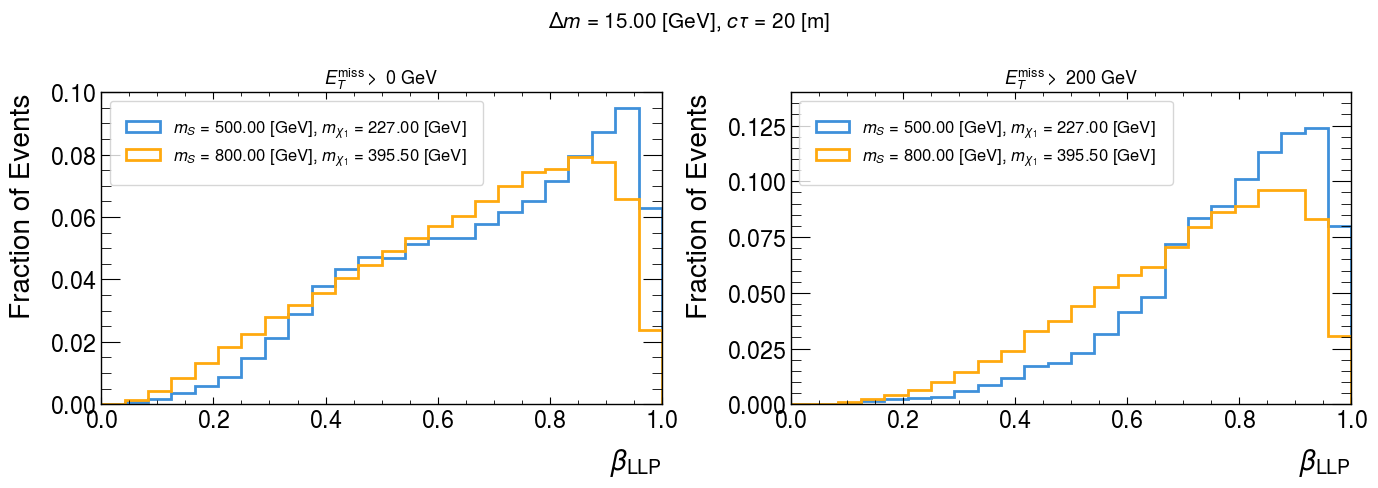

In [51]:

nrows, ncols = 1,2
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(7*ncols, 5*nrows))
axes = axes.flatten() if nrows*ncols > 1 else [axes]
plt.suptitle(common_label,fontsize=15)
for ax,metCut in zip(axes,[0.,200.]):
    ax.set_title(fr'$E_T^{{\rm miss}} >$ {metCut:1.0f} GeV',fontsize=13)
    for df0 in df_filtered:
        df = df0[df0['met'] > metCut]
        short_label = get_labels(df, all_df=df_filtered, full_label=False)[0]
        ax.hist(df['beta'],bins=np.linspace(0.,1.0,25),
             histtype='step',
             weights=[1.0/len(df)]*len(df),
             label=f'{short_label}',linewidth=2)
        # axes.set_yscale('log')
        ax.set_ylabel('Fraction of Events')
        ax.set_xlabel(r'$\beta_{\rm LLP}$')
        ax.legend(loc='upper left',framealpha=0.8,frameon=True,fontsize=12)
        ax.grid()
plt.tight_layout()
plt.show()

# Plots vs deltaM

In [52]:

selectPoints = [{'mS' : 500.0, 'dm' : 15.0, 'm1' : 227.0, 'ctau' : 20.0},  
                {'mS' : 500.0, 'dm' : 100.0, 'm1' : 227.0, 'ctau' : 20.0}]

df_filtered = [closestDF(dfList, point) for point in selectPoints]
common_label = get_labels(df_filtered[0], all_df=df_filtered, full_label=False)[1]

### MET Distribution

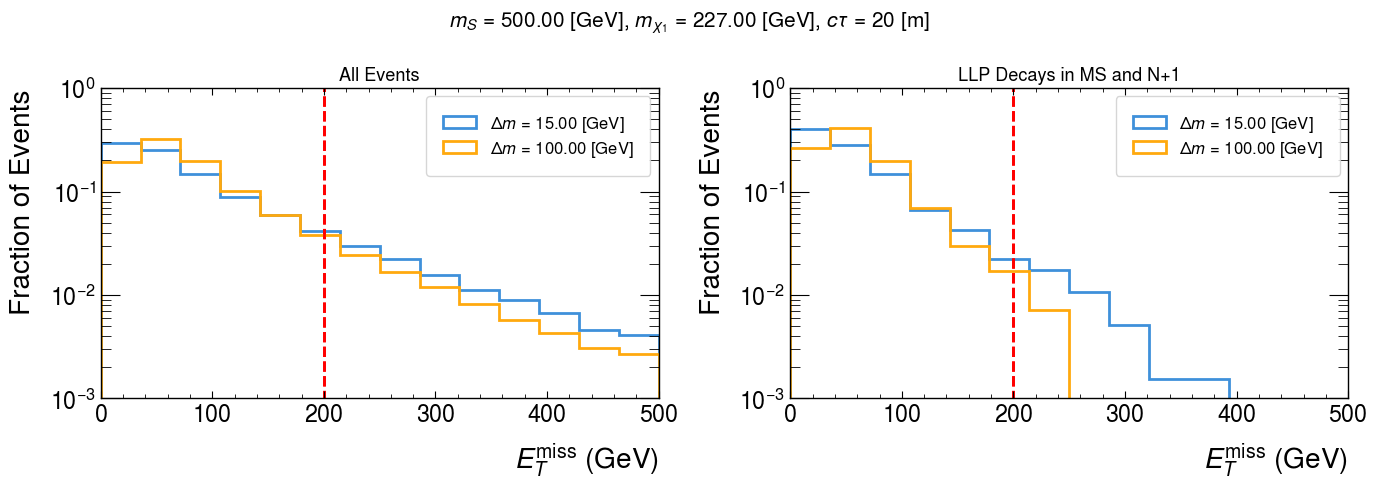

In [53]:

nrows, ncols = 1,2
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(7*ncols, 5*nrows))
axes = axes.flatten() if nrows*ncols > 1 else [axes]
plt.suptitle(common_label,fontsize=15)
for ax,inMS in zip(axes,[False,True]):
    if inMS:
        ax.set_title(fr'LLP Decays in MS and N+1',fontsize=13)
    else:
        ax.set_title(fr'All Events',fontsize=13)
    for df0 in df_filtered:
        if inMS:
            df = df0[df0['in MS'] & df0['delayed']]
        else:
            df = df0
        short_label = get_labels(df, all_df=df_filtered, full_label=False)[0]
        ax.hist(df['met'],bins=np.linspace(0.,500.0,15),
             histtype='step',
             weights=[1.0/len(df)]*len(df),
             label=f'{short_label}',linewidth=2)
        ax.set_yscale('log')
        ax.set_xlabel(r'$E_T^{\rm miss}$ (GeV)')
        ax.set_ylabel('Fraction of Events')
        ax.legend(loc='upper right',framealpha=0.8,frameon=True,fontsize=12)
        ax.set_ylim(1e-3,1.0)
        ax.grid()
        ax.vlines(x=200.,ymin=0.,ymax=1.0,color='red',linestyles='dashed')
plt.tight_layout()
plt.show()

### Boost Distribution

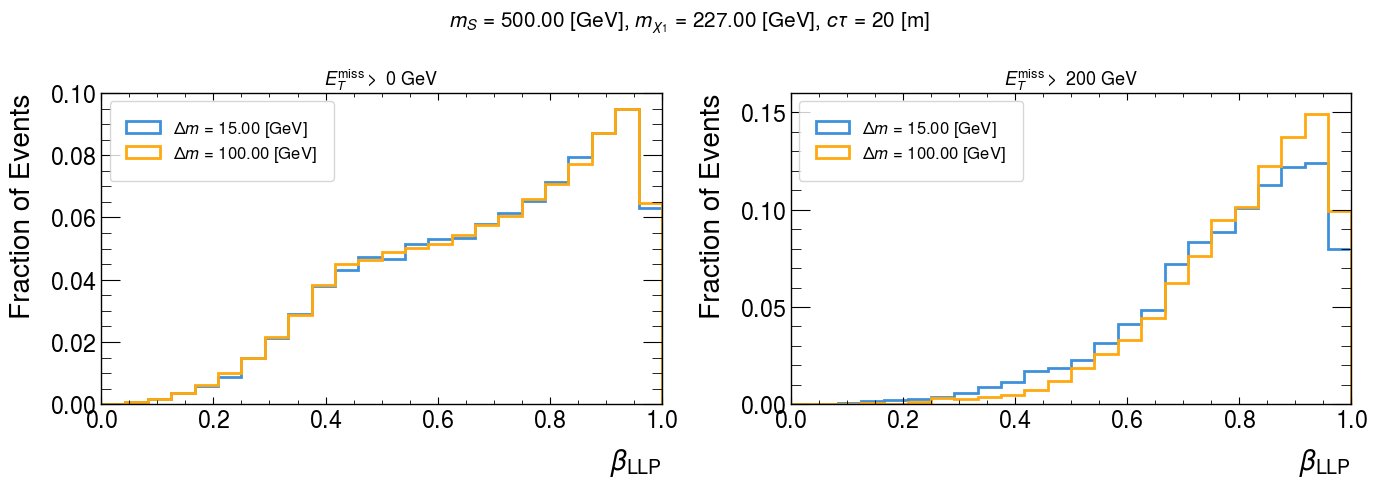

In [54]:

nrows, ncols = 1,2
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(7*ncols, 5*nrows))
axes = axes.flatten() if nrows*ncols > 1 else [axes]
plt.suptitle(common_label,fontsize=15)
for ax,metCut in zip(axes,[0.,200.]):
    ax.set_title(fr'$E_T^{{\rm miss}} >$ {metCut:1.0f} GeV',fontsize=13)
    for df0 in df_filtered:
        df = df0[df0['met'] > metCut]
        short_label = get_labels(df, all_df=df_filtered, full_label=False)[0]
        ax.hist(df['beta'],bins=np.linspace(0.,1.0,25),
             histtype='step',
             weights=[1.0/len(df)]*len(df),
             label=f'{short_label}',linewidth=2)
        # axes.set_yscale('log')
        ax.set_ylabel('Fraction of Events')
        ax.set_xlabel(r'$\beta_{\rm LLP}$')
        ax.legend(loc='upper left',framealpha=0.8,frameon=True,fontsize=12)
        ax.grid()
plt.tight_layout()
plt.show()